# Predicción de Churn — Modelado y Evaluación de Clasificación

**Objetivo:** entrenar un modelo de clasificación binaria que prediga si un cliente abandonará el servicio (*Churn*) y evaluar su desempeño con las métricas vistas en clase.

**Dataset:** *Telco Customer Churn* (IBM): 7.043 clientes de una empresa de telecomunicaciones con datos demográficos, servicios contratados, tipo de contrato y facturación. La variable objetivo es `Churn` (`Yes` / `No`).

**Etapas del notebook**
1. Carga y exploración de los datos
2. Limpieza y preparación
3. División Train/Test (80/20)
4. Entrenamiento de un modelo de **Logistic Regression**
5. Evaluación: Accuracy, Precision, Recall, F1-Score y Matriz de Confusión
6. Interpretación de métricas y conclusión de negocio

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report)

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")

## 1. Carga y exploración de los datos

In [2]:
df = pd.read_csv("data/Telco-Customer-Churn.csv")
print(f"Filas: {df.shape[0]} | Columnas: {df.shape[1]}")
df.head()

Filas: 7043 | Columnas: 21


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
# Distribución de la variable objetivo
churn_counts = df["Churn"].value_counts()
churn_pct = df["Churn"].value_counts(normalize=True).mul(100).round(2)
pd.DataFrame({"clientes": churn_counts, "%": churn_pct})

,clientes,%
Churn,,
No,5174,73.46
Yes,1869,26.54


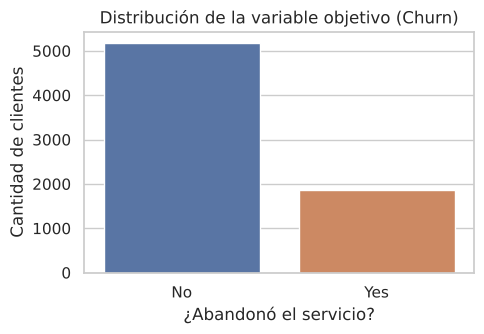

In [4]:
fig, ax = plt.subplots(figsize=(5, 3.5))
sns.countplot(data=df, x="Churn", hue="Churn", palette=["#4C72B0", "#DD8452"], legend=False, ax=ax)
ax.set_title("Distribución de la variable objetivo (Churn)")
ax.set_xlabel("¿Abandonó el servicio?")
ax.set_ylabel("Cantidad de clientes")
plt.tight_layout()
plt.show()

El dataset está **desbalanceado**: aproximadamente 1 de cada 4 clientes abandona el servicio. Esto es importante para la evaluación: un modelo que siempre prediga "No" tendría ~73% de Accuracy sin detectar ni un solo cliente en riesgo, por eso no alcanza con mirar solo el Accuracy.

## 2. Limpieza y preparación

In [5]:
# TotalCharges viene como texto: tiene espacios en blanco en clientes nuevos (tenure = 0)
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print("Valores nulos en TotalCharges:", df["TotalCharges"].isna().sum())

df = df.dropna(subset=["TotalCharges"]).reset_index(drop=True)
print("Filas después de la limpieza:", len(df))

# Variable objetivo binaria: 1 = abandona, 0 = se queda
y = (df["Churn"] == "Yes").astype(int)
# customerID es un identificador, no aporta información predictiva
X = df.drop(columns=["customerID", "Churn"])

num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
cat_cols = [c for c in X.columns if c not in num_cols]
print("Variables numéricas:", num_cols)
print("Variables categóricas:", len(cat_cols))

Valores nulos en TotalCharges: 11
Filas después de la limpieza: 7032
Variables numéricas: ['tenure', 'MonthlyCharges', 'TotalCharges']
Variables categóricas: 16


## 3. División Train/Test (80/20)

Se usa `stratify=y` para que ambos conjuntos mantengan la misma proporción de clientes que abandonan, y `random_state` fijo para que los resultados sean reproducibles.

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

print(f"Train: {X_train.shape[0]} filas ({y_train.mean():.1%} churn)")
print(f"Test:  {X_test.shape[0]} filas ({y_test.mean():.1%} churn)")

Train: 5625 filas (26.6% churn)
Test:  1407 filas (26.6% churn)


## 4. Entrenamiento del modelo: Logistic Regression

Se arma un `Pipeline` que:
- **escala** las variables numéricas (`StandardScaler`),
- aplica **One-Hot Encoding** a las categóricas,
- entrena una **Regresión Logística**.

El preprocesamiento se ajusta solo con los datos de entrenamiento, evitando filtrar información del set de prueba.

In [7]:
preprocesador = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
])

modelo = Pipeline([
    ("preprocesamiento", preprocesador),
    ("clasificador", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
])

modelo.fit(X_train, y_train)
y_pred = modelo.predict(X_test)
print("Modelo entrenado correctamente.")

Modelo entrenado correctamente.


## 5. Evaluación de métricas sobre el set de prueba

In [8]:
metricas = {
    "Accuracy":  accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred),
    "Recall":    recall_score(y_test, y_pred),
    "F1-Score":  f1_score(y_test, y_pred),
}
tabla_metricas = pd.DataFrame.from_dict(metricas, orient="index", columns=["Valor"]).round(4)
tabla_metricas

,Valor
Accuracy,0.8045
Precision,0.6495
Recall,0.5749
F1-Score,0.6099


In [9]:
print(classification_report(y_test, y_pred, target_names=["No Churn (0)", "Churn (1)"], digits=4))

              precision    recall  f1-score   support

No Churn (0)     0.8522    0.8877    0.8696      1033
   Churn (1)     0.6495    0.5749    0.6099       374

    accuracy                         0.8045      1407
   macro avg     0.7509    0.7313    0.7398      1407
weighted avg     0.7984    0.8045    0.8006      1407



### Matriz de Confusión

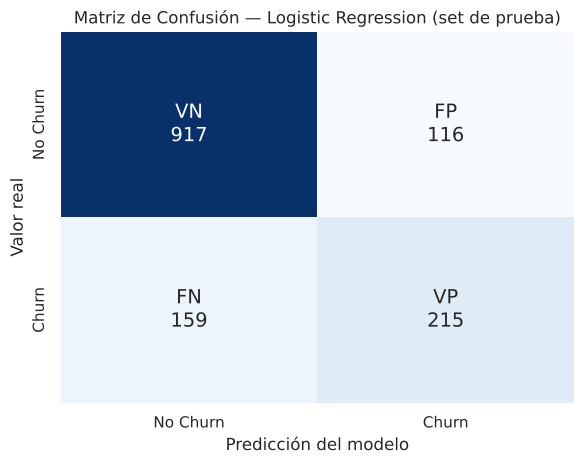

Verdaderos Negativos (VN): 917  -> clientes que se quedan, bien identificados
Falsos Positivos   (FP): 116  -> se predijo abandono, pero el cliente se queda
Falsos Negativos   (FN): 159  -> el cliente SE VA y el modelo no lo detectó
Verdaderos Positivos (VP): 215  -> clientes que se van, correctamente detectados


In [10]:
cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()

etiquetas = np.array([
    [f"VN\n{tn}", f"FP\n{fp}"],
    [f"FN\n{fn}", f"VP\n{tp}"],
])

fig, ax = plt.subplots(figsize=(6, 4.8))
sns.heatmap(cm, annot=etiquetas, fmt="", cmap="Blues", cbar=False, annot_kws={"size": 14},
            xticklabels=["No Churn", "Churn"], yticklabels=["No Churn", "Churn"], ax=ax)
ax.set_xlabel("Predicción del modelo")
ax.set_ylabel("Valor real")
ax.set_title("Matriz de Confusión — Logistic Regression (set de prueba)")
plt.tight_layout()
plt.show()

print(f"Verdaderos Negativos (VN): {tn}  -> clientes que se quedan, bien identificados")
print(f"Falsos Positivos   (FP): {fp}  -> se predijo abandono, pero el cliente se queda")
print(f"Falsos Negativos   (FN): {fn}  -> el cliente SE VA y el modelo no lo detectó")
print(f"Verdaderos Positivos (VP): {tp}  -> clientes que se van, correctamente detectados")

## 6. Interpretación: ¿qué métrica es la más importante para Churn?

**La métrica más importante para este problema es el Recall** (sensibilidad) de la clase positiva (*Churn*).

$$\text{Recall} = \frac{VP}{VP + FN}$$

El Recall responde: *de todos los clientes que realmente se van, ¿qué porcentaje detecta el modelo?*

**¿Por qué? Por el costo de los falsos negativos.** En Churn, los dos tipos de error no cuestan lo mismo:

| Error | Qué significa | Costo para el negocio |
|---|---|---|
| **Falso Negativo (FN)** | El cliente se va y el modelo dijo que se quedaba | **Alto**: se pierde al cliente y todos sus ingresos futuros (*Customer Lifetime Value*), sin haber tenido la oportunidad de intervenir. Además, captar un cliente nuevo suele costar varias veces más que retener uno existente. |
| **Falso Positivo (FP)** | El cliente se queda, pero el modelo dijo que se iba | **Bajo**: se le ofrece una acción de retención (descuento, llamada, beneficio) que no hacía falta. Es un gasto acotado y hasta puede mejorar la satisfacción del cliente. |

Como un falso negativo es mucho más caro que un falso positivo, conviene priorizar un modelo que **minimice los FN**, es decir, que **maximice el Recall**, aun a costa de perder algo de Precision. El **Accuracy** no es buena guía porque el dataset está desbalanceado, y el **F1-Score** es útil como métrica de equilibrio, pero pondera igual Precision y Recall, cuando en este negocio los errores no pesan lo mismo.

### Ajuste orientado al negocio: `class_weight="balanced"`

Siguiendo esa lógica, se entrena una variante del mismo modelo que le da más peso a la clase minoritaria (Churn) para penalizar más los falsos negativos, y se compara con el modelo base.

In [11]:
modelo_balanceado = Pipeline([
    ("preprocesamiento", preprocesador),
    ("clasificador", LogisticRegression(max_iter=1000, class_weight="balanced",
                                        random_state=RANDOM_STATE)),
])
modelo_balanceado.fit(X_train, y_train)
y_pred_bal = modelo_balanceado.predict(X_test)

def resumen(y_true, y_hat):
    tn, fp, fn, tp = confusion_matrix(y_true, y_hat).ravel()
    return {
        "Accuracy": accuracy_score(y_true, y_hat),
        "Precision": precision_score(y_true, y_hat),
        "Recall": recall_score(y_true, y_hat),
        "F1-Score": f1_score(y_true, y_hat),
        "Falsos Negativos": fn,
        "Falsos Positivos": fp,
    }

comparacion = pd.DataFrame({
    "LogReg base": resumen(y_test, y_pred),
    "LogReg balanceada": resumen(y_test, y_pred_bal),
}).round(4).astype(object)
errores = ["Falsos Negativos", "Falsos Positivos"]
comparacion.loc[errores] = comparacion.loc[errores].astype(int)
comparacion

,LogReg base,LogReg balanceada
Accuracy,0.8045,0.7257
Precision,0.6495,0.4901
Recall,0.5749,0.7968
F1-Score,0.6099,0.6069
Falsos Negativos,159,76
Falsos Positivos,116,310


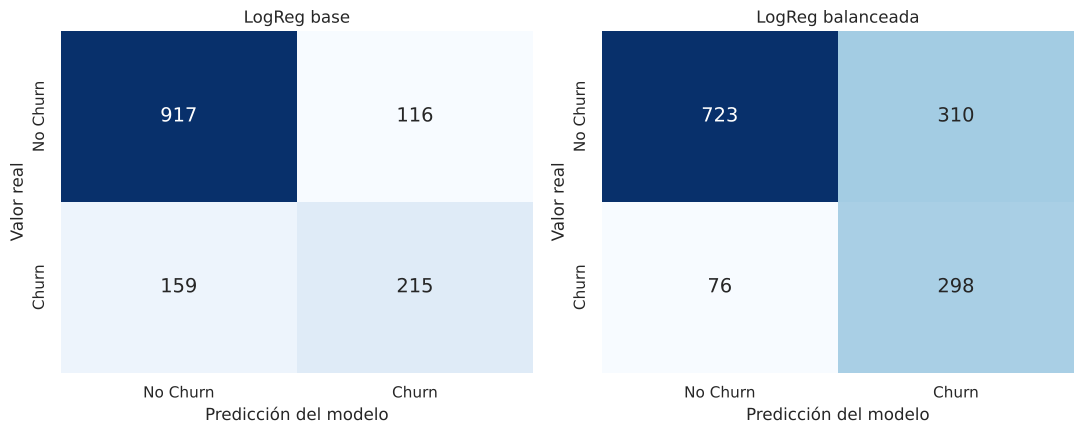

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (titulo, pred) in zip(axes, [("LogReg base", y_pred), ("LogReg balanceada", y_pred_bal)]):
    sns.heatmap(confusion_matrix(y_test, pred), annot=True, fmt="d", cmap="Blues", cbar=False,
                annot_kws={"size": 14}, xticklabels=["No Churn", "Churn"],
                yticklabels=["No Churn", "Churn"], ax=ax)
    ax.set_title(titulo)
    ax.set_xlabel("Predicción del modelo")
    ax.set_ylabel("Valor real")
plt.tight_layout()
plt.show()

## 7. Conclusión: métricas e impacto en el negocio

**Resultados del modelo base (Logistic Regression) en el set de prueba (1407 clientes, 374 de los cuales abandonaron):**

| Métrica | Valor | Lectura de negocio |
|---|---|---|
| Accuracy | 80,5% | Acierta en 4 de cada 5 clientes, pero está inflado por la clase mayoritaria (No Churn). |
| Precision | 65,0% | De los clientes que el modelo marca "en riesgo", ~65 de cada 100 realmente se van: las campañas de retención estarían bien dirigidas. |
| Recall | 57,5% | Detecta solo ~57% de los clientes que se van. |
| F1-Score | 61,0% | Equilibrio moderado entre Precision y Recall. |

**Impacto en el negocio.** Con el modelo base hay **159 falsos negativos**: 159 de los 374 clientes que abandonaron (42,5%) pasaron desapercibidos y se habrían perdido sin ninguna acción de retención. Ese es el error más costoso, porque implica perder ingresos recurrentes y tener que pagar el costo (mayor) de captar clientes nuevos para reemplazarlos.

Al ajustar el modelo con `class_weight="balanced"`, priorizando el Recall:
- el **Recall sube de 57,5% a 79,7%**, y los **falsos negativos bajan de 159 a 76**: se detectan 83 clientes más que se iban a ir;
- a cambio, la Precision baja a 49,0% y los falsos positivos suben de 116 a 310, y el Accuracy cae a 72,6%. Es decir, se ofrecerían beneficios de retención a más clientes que no los necesitaban.

Este intercambio conviene siempre que el costo de una acción de retención (un descuento o una llamada) sea menor que el valor de un cliente perdido, que es lo habitual en servicios de suscripción. Por eso, **para el problema de Churn recomendamos guiarse por el Recall** y elegir la versión balanceada del modelo como punto de partida, ajustando el umbral de decisión según el presupuesto de retención disponible.

**Próximos pasos posibles:** probar un Random Forest, ajustar el umbral de probabilidad y estimar el costo real de FN y FP con datos de la empresa para optimizar la ganancia esperada.